# Roman configurations

We configure `SLSIM_ROMAN_PSF_DIRECTORY` to point to a local PSF cache. The public [`cached_webb_psf` collection](https://github.com/LSST-strong-lensing/data_public/tree/main/webbpsf/cached_webb_psf) provides precomputed kernels for F062, F106, F129, and F184. Our examples also render F158. When the cache has no matching F158 kernel, SLSim generates it with STPSF, which can be slow.

In [ ]:
import numpy as np
import os
import matplotlib.pyplot as plt

import slsim
from slsim.Lenses.lens_pop import LensPop
from slsim.Pipelines.roman_speclite import configure_roman_filters
from slsim.Pipelines.roman_speclite import filter_names
import speclite
from astropy.cosmology import FlatLambdaCDM
from astropy.units import Quantity
import slsim.Sources as sources
import slsim.Deflectors as deflectors
import slsim.Pipelines as pipelines
import corner
from astropy.table import vstack
# Set STPSF_PATH in the environment when using a custom STPSF data directory.

%matplotlib inline

In [2]:
import galsim
from galsim import Image, InterpolatedImage, roman
print(f"✓ GalSim successfully imported, version: {galsim.__version__}")
print(f"✓ InterpolatedImage available: {InterpolatedImage}")

✓ GalSim successfully imported, version: 2.8.3
✓ InterpolatedImage available: <class 'galsim.interpolatedimage.InterpolatedImage'>


In [3]:
from mejiro.instruments.roman import Roman

Roman.load_speclite_filters()

# Import default Roman Space Telescope configuration
skypy_config = 'roman-like.yml'

In [4]:
# define a cosmology
cosmo = FlatLambdaCDM(H0=70, Om0=0.3)

# define a sky area
sky_area = Quantity(value=0.5, unit="deg2") #survey area 

#sky area samples
sky_area_samples = Quantity(value=0.5, unit="deg2") #catalog/simulation area

# define limits in the intrinsic deflector and source population (in addition to the skypy config file)
kwargs_deflector_cut = {"band": "F062", "band_max": 25, "z_min": 0.01, "z_max": 3.0}
kwargs_source_cut = {"band": "F062", "band_max": 28, "z_min": 0.01, "z_max": 5.0}

# run skypy pipeline and make galaxy-galaxy population class
galaxy_simulation_pipeline = pipelines.SkyPyPipeline(
    skypy_config=skypy_config,
    sky_area=sky_area_samples,
    filters=None,
)

blue_plus_red_galaxies = vstack([galaxy_simulation_pipeline.blue_galaxies, galaxy_simulation_pipeline.red_galaxies])

# lens_galaxies = deflectors.EllipticalLensGalaxies(
#     galaxy_list=galaxy_simulation_pipeline.red_galaxies,
#     kwargs_cut=kwargs_deflector_cut,
#     kwargs_mass2light={},
#     cosmo=cosmo,
#     sky_area=sky_area,
# )

#now use the blue and the red galaxies instead of simply the elliptical galaxies

lens_galaxies = deflectors.AllLensGalaxies(
    red_galaxy_list=galaxy_simulation_pipeline.red_galaxies,
    blue_galaxy_list=galaxy_simulation_pipeline.blue_galaxies,
    kwargs_cut=kwargs_deflector_cut,
    kwargs_mass2light={},
    cosmo=cosmo,
    sky_area=sky_area_samples,
)

source_galaxies = sources.Galaxies(
    galaxy_list=  blue_plus_red_galaxies, #galaxy_simulation_pipeline.blue_galaxies,
    kwargs_cut=kwargs_source_cut,
    cosmo=cosmo,
    sky_area=sky_area_samples,
    catalog_type="skypy",
    source_size=None,
)

lens_pop = LensPop(
    deflector_population=lens_galaxies,
    source_population=source_galaxies,
    cosmo=cosmo,
    sky_area=sky_area,
)

<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Deflectors/DeflectorPopulation/all_lens_galaxies.py:56: UserWarning: Angular size is converted to arcsec because provided input_catalog_type is skypy. If this is not correct, please refer to the documentation of the class you are using
  red_galaxy_list = catalog_with_angular_size_in_arcsec(
<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Deflectors/DeflectorPopulation/all_lens_galaxies.py:59: UserWarning: Angular size is converted to arcsec because provided input_catalog_type is skypy. If this is not correct, please refer to the documentation of the class you are using
  blue_galaxy_list = catalog_with_angular_size_in_arcsec(


In [ ]:
psf_directory = os.environ.get("SLSIM_ROMAN_PSF_DIRECTORY")

<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Util/ParamDistributions/kext_gext_distributions.py:126: UserWarning: No file found, provide 0 instead.
  warnings.warn("No file found, provide 0 instead.")


<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Util/ParamDistributions/kext_gext_distributions.py:126: UserWarning: No file found, provide 0 instead.
  warnings.warn("No file found, provide 0 instead.")
<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Util/ParamDistributions/kext_gext_distributions.py:126: UserWarning: No file found, provide 0 instead.
  warnings.warn("No file found, provide 0 instead.")
<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Util/ParamDistributions/kext_gext_distributions.py:126: UserWarning: No file found, provide 0 instead.
  warnings.warn("No file found, provide 0 instead.")
<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Util/ParamDistributions/kext_gext_distributions.py:126: UserWarning: No file found, provide 0 instead.
  warnings.warn("No file found, provide 0 instead.")
<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Util/ParamDistributions/kext_gext_distributions.py:126: UserWarning: No file foun

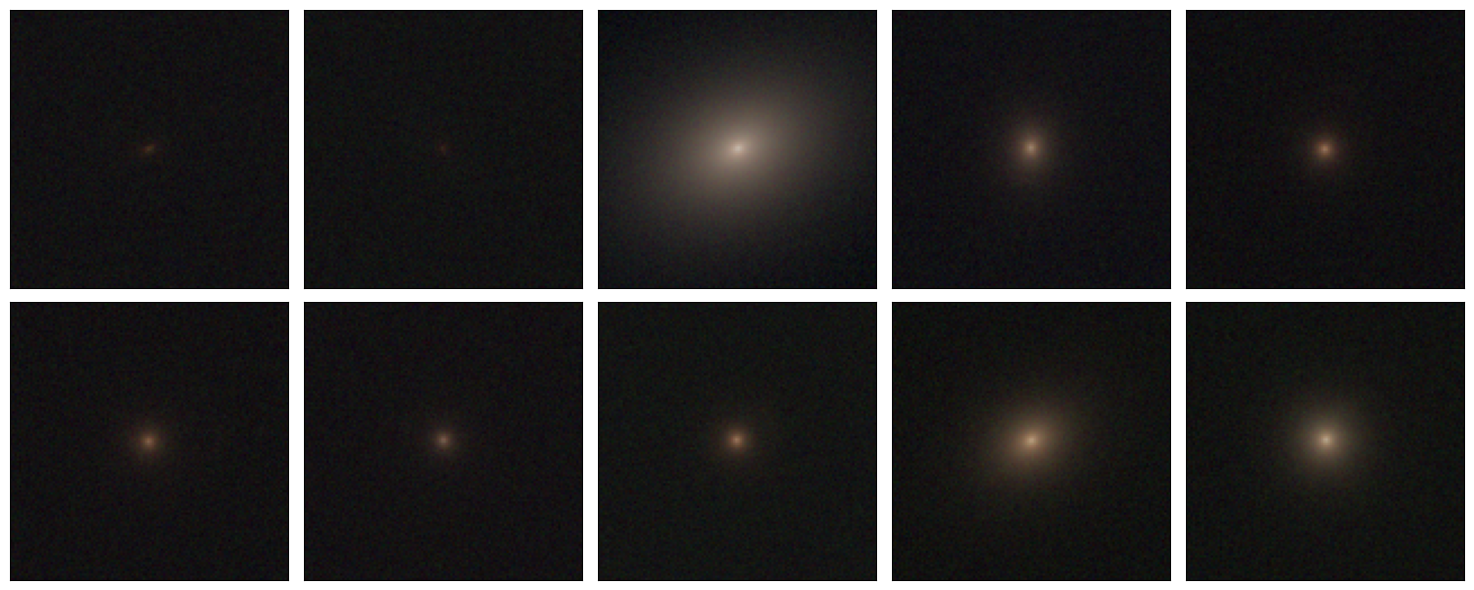

In [ ]:
# kwargs_lens_cut_plot = {
#     "min_image_separation": 2.0,
#     "max_image_separation": 10,
#     "mag_arc_limit": {"F184": 21, "F129": 21, "F062": 21},
# }

kwargs_lens_cut_plot = {
    "min_image_separation": 2.0, # angular distance between the lensed images of the same source
    "max_image_separation": 10,
    "mag_arc_limit": {"F158": 25, "F129": 25, "F106": 25},
}
#might want to mess with the mag_arc_limit and change it to (24,25)26 for the roman limit 

# Generating images can be very slow due to having to use STPSF to generate PSFs each time
# Provide SLSIM_ROMAN_PSF_DIRECTORY for a local precomputed PSF cache; otherwise SLSim uses its default.

# make montage of realizations
gg_plot = LensingPlots(
    lens_pop, num_pix=124, observatory="Roman", psf_directory=psf_directory
)

fig, axes = gg_plot.plot_montage(
    rgb_band_list=["F158", "F129", "F106"],
    add_noise=True,
    n_horizont=5,
    n_vertical=2,
    kwargs_lens_cut=kwargs_lens_cut_plot,
)
plt.show()

<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Util/ParamDistributions/kext_gext_distributions.py:126: UserWarning: No file found, provide 0 instead.
  warnings.warn("No file found, provide 0 instead.")


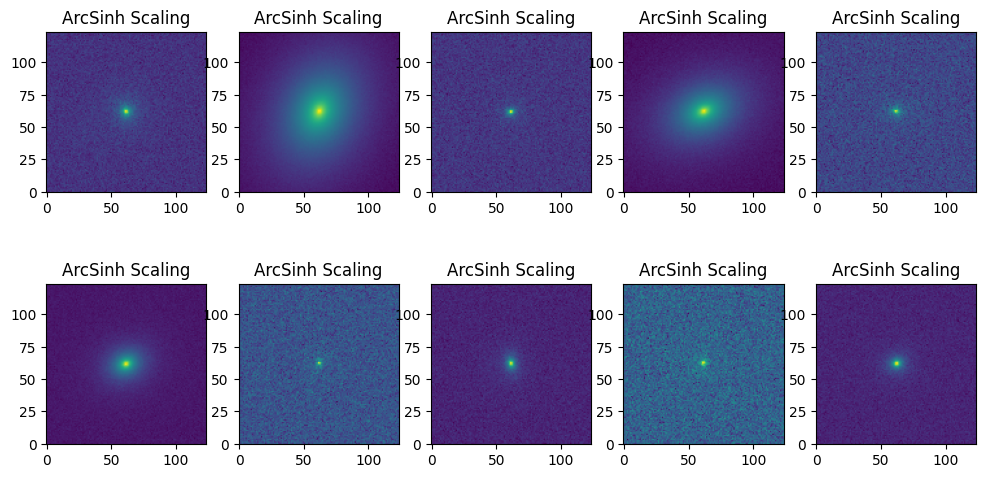

In [7]:
#now plot the same thing but use the arc sinh scaling
#select 10 lenses at random 

test_lens_list = []
for _ in range(10):
    lens = lens_pop.select_lens_at_random(**kwargs_lens_cut_plot)
    test_lens_list.append(lens)

fig, axes = plt.subplots(2, 5, figsize=(12, 6))
#plot the 10 lenses
for i, lens in enumerate(test_lens_list):
    arcsinh_scaling_lens  =  simulate_roman_image(lens, band="F129", num_pix=124, oversample=5, add_noise=True, with_deflector=True)
    axes[i//5, i%5].imshow(np.arcsinh(arcsinh_scaling_lens), origin="lower", cmap="viridis")
    #axes[i//5, i%5].colorbar()
    axes[i//5, i%5].set_title("ArcSinh Scaling")
plt.show()

#TODO: try to plot the image with the deflector only and the source only to see if there is a ring structure



<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Util/ParamDistributions/kext_gext_distributions.py:126: UserWarning: No file found, provide 0 instead.
  warnings.warn("No file found, provide 0 instead.")


<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Util/ParamDistributions/kext_gext_distributions.py:126: UserWarning: No file found, provide 0 instead.
  warnings.warn("No file found, provide 0 instead.")
<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Util/ParamDistributions/kext_gext_distributions.py:126: UserWarning: No file found, provide 0 instead.
  warnings.warn("No file found, provide 0 instead.")
<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Util/ParamDistributions/kext_gext_distributions.py:126: UserWarning: No file found, provide 0 instead.
  warnings.warn("No file found, provide 0 instead.")
<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Util/ParamDistributions/kext_gext_distributions.py:126: UserWarning: No file found, provide 0 instead.
  warnings.warn("No file found, provide 0 instead.")
<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Util/ParamDistributions/kext_gext_distributions.py:126: UserWarning: No file foun

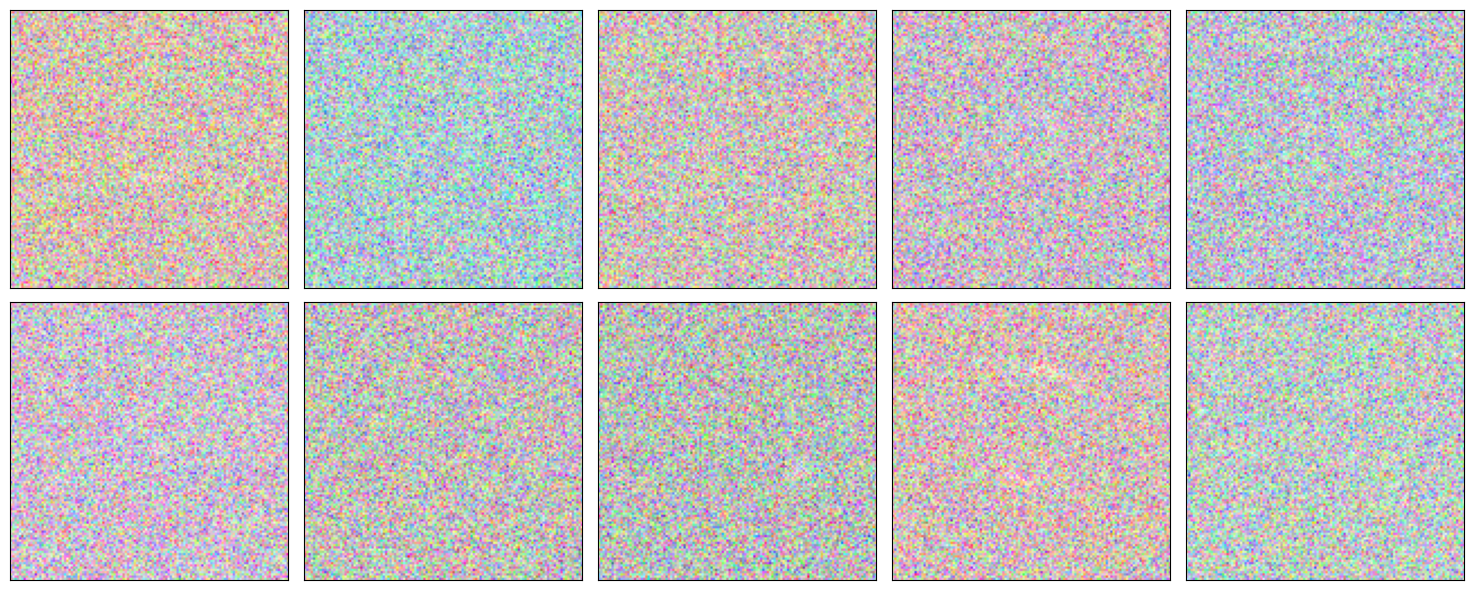

In [8]:
# make montage of realizations without the deflector

gg_plot = LensingPlots(
    lens_pop, num_pix=124, observatory="Roman", psf_directory=psf_directory, with_deflector= False
)

fig, axes = gg_plot.plot_montage(
    rgb_band_list=["F158", "F129", "F106"],
    add_noise=True,
    n_horizont=5,
    n_vertical=2,
    kwargs_lens_cut=kwargs_lens_cut_plot,
    stretch=0.5,  # RGB scaling for faint sources
    Q=2, 
)
plt.show()

<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Util/ParamDistributions/kext_gext_distributions.py:126: UserWarning: No file found, provide 0 instead.
  warnings.warn("No file found, provide 0 instead.")
<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/astropy/visualization/lupton_rgb.py:645: RuntimeWarning: invalid value encountered in divide
  fInorm = np.where(Int <= 0, 0, np.true_divide(fI, Int))
<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Util/ParamDistributions/kext_gext_distributions.py:126: UserWarning: No file found, provide 0 instead.
  warnings.warn("No file found, provide 0 instead.")
<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/astropy/visualization/lupton_rgb.py:645: RuntimeWarning: invalid value encountered in divide
  fInorm = np.where(Int <= 0, 0, np.true_divide(fI, Int))
<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Util/ParamDistributions/kext_gext_distributions.py:126: UserWarning: No file found, provide 0 instead.


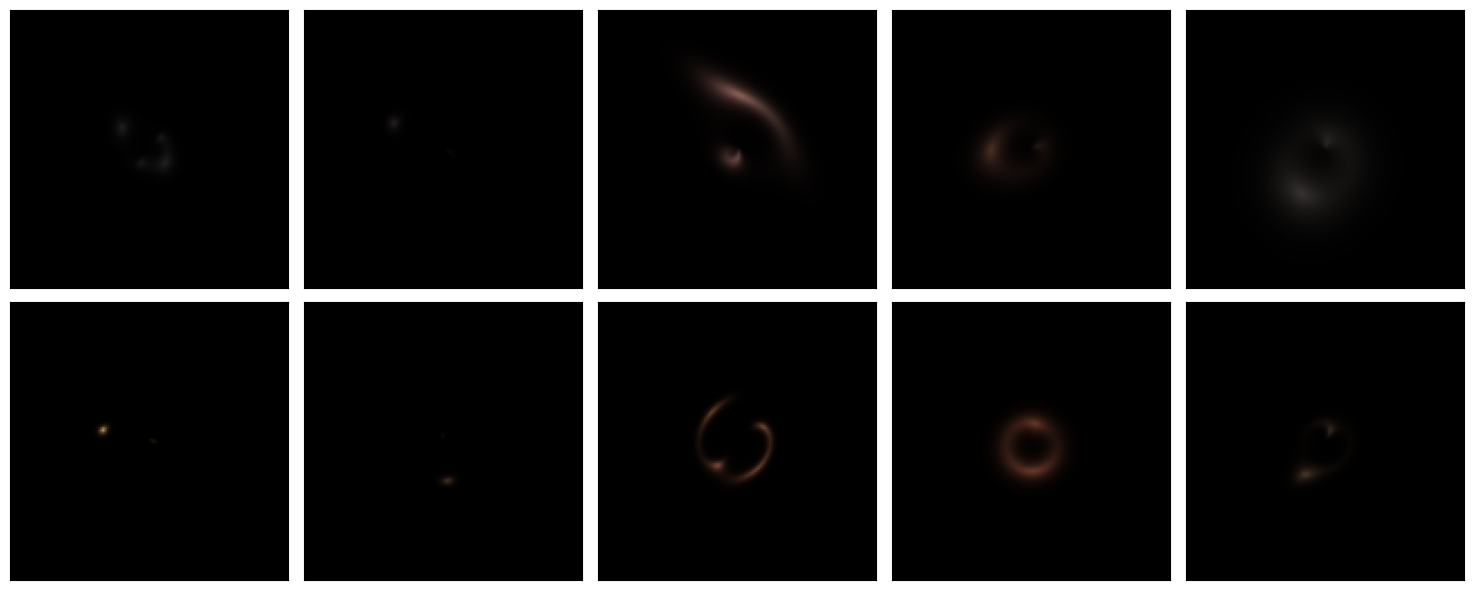

In [10]:
#plot it without deflector or noise 

gg_plot = LensingPlots(
    lens_pop, num_pix=124, observatory="Roman", psf_directory=psf_directory, with_deflector= False
)

fig, axes = gg_plot.plot_montage(
    rgb_band_list=["F158", "F129", "F106"],
    add_noise=False,
    n_horizont=5,
    n_vertical=2,
    kwargs_lens_cut=kwargs_lens_cut_plot,
    stretch=0.5,  # RGB scaling for faint sources
    Q=2, 
)
plt.show()

Text(0.5, 1.0, 'Deflector Only with noise')

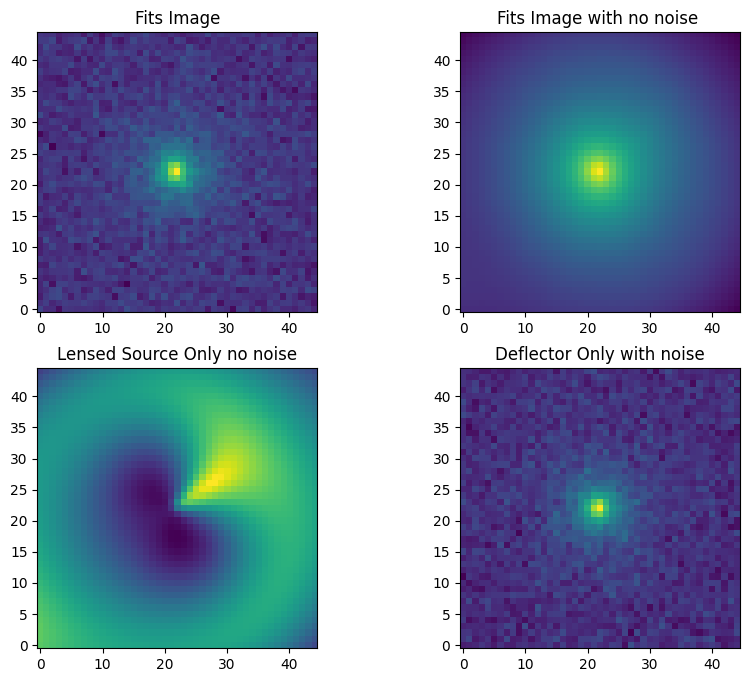

In [11]:
#plot different images
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

#fits image 
single_image = simulate_roman_image(
    test_lens_list[0], band="F106", num_pix=45, oversample=5, add_noise=True
)
axes[0,0].imshow(np.log10(single_image), origin="lower")
#axes[0].colorbar()
axes[0,0].set_title("Fits Image")


#fits image 
single_image = simulate_roman_image(
    test_lens_list[0], band="F106", num_pix=45, oversample=5, add_noise=False
)
axes[0,1].imshow(np.log10(single_image), origin="lower")
#axes[0].colorbar()
axes[0,1].set_title("Fits Image with no noise ")

#lensed source only
single_image = simulate_roman_image(
    test_lens_list[0], band="F106", num_pix=45, oversample=5, add_noise=False, with_deflector=False
)
axes[1,0].imshow(np.log10(single_image), origin="lower")
#axes[1].colorbar()
axes[1,0].set_title("Lensed Source Only no noise")

#deflector only
single_image = simulate_roman_image(
    test_lens_list[0], band="F106", num_pix=45, oversample=5, add_noise=True, with_deflector=True, with_source=False
)
axes[1,1].imshow(np.log10(single_image), origin="lower")
#axes[2].colorbar()
axes[1,1].set_title("Deflector Only with noise")




In [12]:
#get the keys of the test_lens_list
keys = test_lens_list[0].__dict__.keys()
print(keys)


dict_keys(['deflector', '_source', 'source_number', 'max_redshift_source_class', '_max_redshift_source_index', 'los_class', 'cosmo', '_lens_equation_solver', '_magnification_limit', '_lens_cosmo', '_theta_E_list', '_kwargs_lens', '_lens_mass_model_list', '_ps_image_position_list'])


In [ ]:
#load the metadata (deflector_redshift, source_redshift, einstein_radius, deflector_velocity_dispersion, deflector_stellar_mass) of the test_lens_list
parameters = {}
keys = ["deflector_redshift", "source_redshift", "einstein_radius", "deflector_velocity_dispersion", "deflector_stellar_mass", "deflector_magnitude", "source_magnitude"]
for k in keys:
    parameters[k] = []

for lens in test_lens_list:
    parameters[keys[0]].append(lens.deflector_redshift)
    parameters[keys[1]].append(lens.source_redshift_list[0])
    parameters[keys[2]].append(lens.einstein_radius[0])
    parameters[keys[3]].append(lens.deflector_velocity_dispersion())
    parameters[keys[4]].append(lens.deflector_stellar_mass())
    parameters[keys[5]].append(lens.deflector_magnitude(band="F129"))
    parameters[keys[6]].append(lens.extended_source_magnitude(band="F129", lensed=True)[0])
print(parameters)


{'deflector_redshift': [1.1577664249507538, 0.05634922621286775, 1.168763568702098, 0.09385381487518715, 1.3428218446116025, 0.22721091424221798, 1.88260971709183, 0.6750773109808469, 1.7089182712767375, 0.7136569267278087], 'source_redshift': [3.248822459652357, 3.7881475761230057, 4.760439672107733, 3.316139911396915, 2.854590511814046, 2.676310896293128, 4.843223916730715, 4.25222680271496, 4.097404670780319, 2.508553173007335], 'einstein_radius': [np.float64(2.392845112949563), np.float64(1.0124831225722555), np.float64(1.2155535152903025), np.float64(1.0810909088084846), np.float64(1.087526357114193), np.float64(1.1947040782598934), np.float64(1.22979748209646), np.float64(1.062344377808965), np.float64(1.16030101768314), np.float64(1.307882350603832)], 'deflector_velocity_dispersion': [np.float64(433.01045239056964), np.float64(190.6318952141807), np.float64(285.6211729634224), np.float64(199.61241089977722), np.float64(330.02264593850805), np.float64(221.14448972779311), np.floa

In [14]:
for key in parameters.keys():
    print(key+":", parameters[key])


deflector_redshift: [1.1577664249507538, 0.05634922621286775, 1.168763568702098, 0.09385381487518715, 1.3428218446116025, 0.22721091424221798, 1.88260971709183, 0.6750773109808469, 1.7089182712767375, 0.7136569267278087]
source_redshift: [3.248822459652357, 3.7881475761230057, 4.760439672107733, 3.316139911396915, 2.854590511814046, 2.676310896293128, 4.843223916730715, 4.25222680271496, 4.097404670780319, 2.508553173007335]
einstein_radius: [np.float64(2.392845112949563), np.float64(1.0124831225722555), np.float64(1.2155535152903025), np.float64(1.0810909088084846), np.float64(1.087526357114193), np.float64(1.1947040782598934), np.float64(1.22979748209646), np.float64(1.062344377808965), np.float64(1.16030101768314), np.float64(1.307882350603832)]
deflector_velocity_dispersion: [np.float64(433.01045239056964), np.float64(190.6318952141807), np.float64(285.6211729634224), np.float64(199.61241089977722), np.float64(330.02264593850805), np.float64(221.14448972779311), np.float64(349.4824

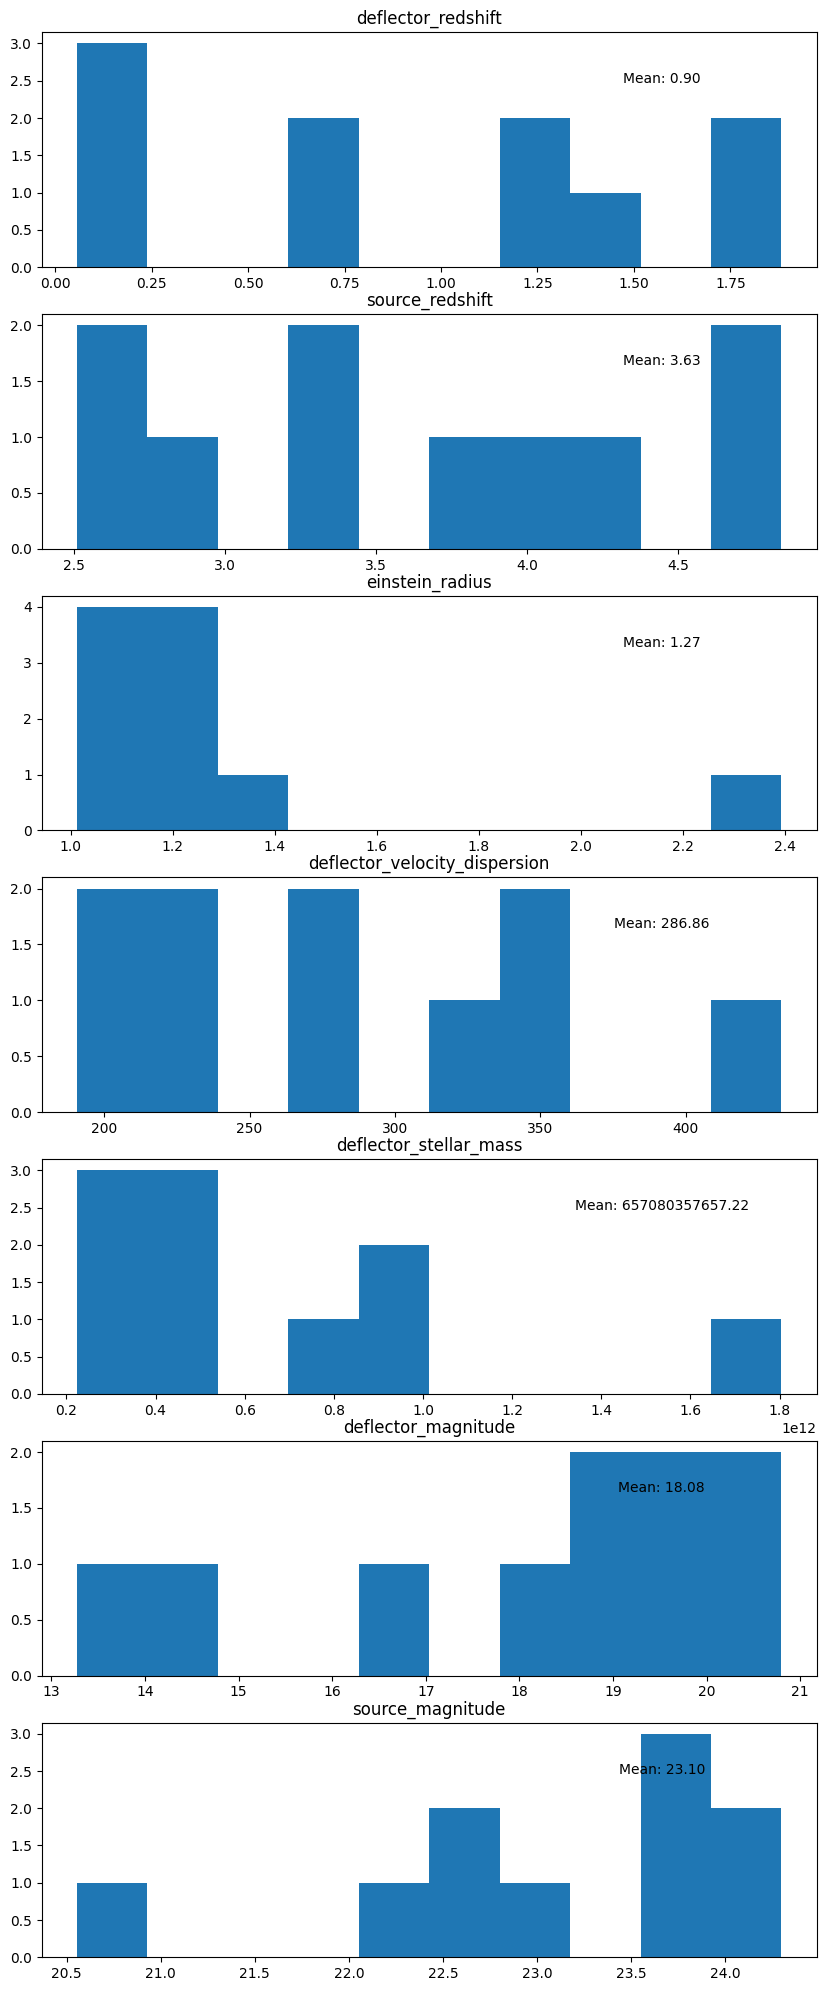

In [15]:
#plot a histogram of the parameters

fig, axes = plt.subplots(7, 1, figsize=(10, 25))

for i, key in enumerate(parameters.keys()):
    axes[i].hist(parameters[key], bins=10)
    axes[i].set_title(key)
    axes[i].text(0.8, 0.8, f"Mean: {np.mean(parameters[key]):.2f}", ha='center', va='center', transform=axes[i].transAxes)
plt.show()



In [16]:

# Same as your simulation
num_pix_sim = 124 + 6  # simulate_roman_image adds 6
delta_pix = 0.11       # arcsec/pixel
center_pix = (num_pix_sim - 1) / 2.0  # 64.5 for 130

def arcsec_to_pixel(x_arcsec, y_arcsec, center=center_pix, scale=delta_pix):
    """Convert angular position (arcsec) to 0-indexed pixel coordinates."""
    pix_x = x_arcsec / scale + center
    pix_y = y_arcsec / scale + center
    return pix_x, pix_y

Lens 0: source flux = 11.03, source mag = 23.34
Lens 1: source flux = 4.98, source mag = 24.21
Lens 2: source flux = 3.56, source mag = 24.57
Lens 3: source flux = 2.26, source mag = 25.06
Lens 4: source flux = 1.80, source mag = 25.31
Lens 5: source flux = 4.35, source mag = 24.35
Lens 6: source flux = 3.18, source mag = 24.69
Lens 7: source flux = 7.53, source mag = 23.76
Lens 8: source flux = 2.08, source mag = 25.15
Lens 9: source flux = 2.53, source mag = 24.94


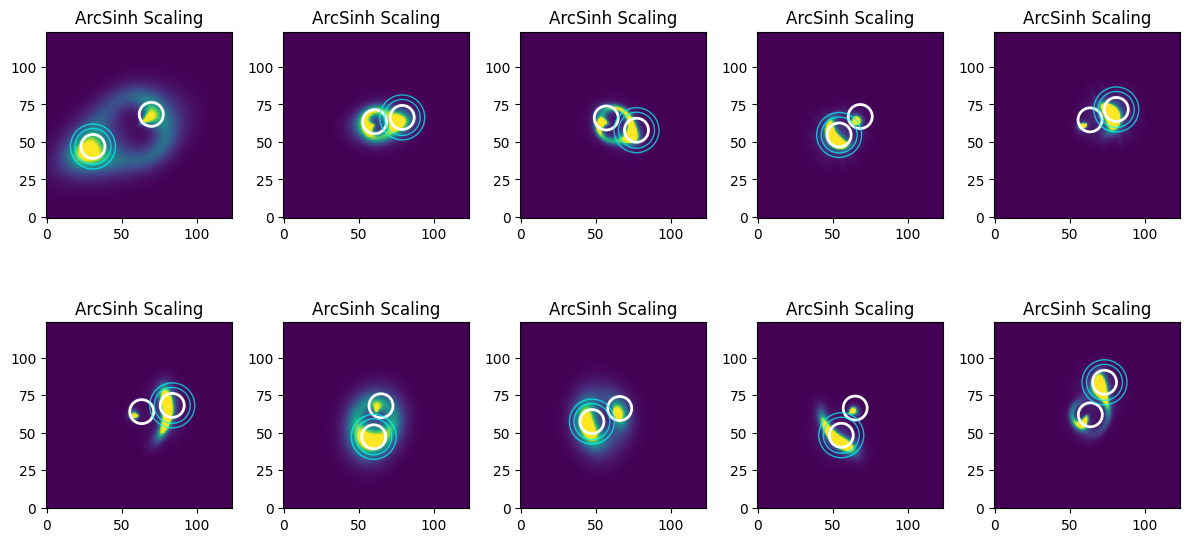

Lens 0: measured mag = 23.34, metadata mag = 20.56
Lens 1: measured mag = 24.21, metadata mag = 22.63
Lens 2: measured mag = 24.57, metadata mag = 23.59
Lens 3: measured mag = 25.06, metadata mag = 24.30
Lens 4: measured mag = 25.31, metadata mag = 24.26
Lens 5: measured mag = 24.35, metadata mag = 23.00
Lens 6: measured mag = 24.69, metadata mag = 22.74
Lens 7: measured mag = 23.76, metadata mag = 22.33
Lens 8: measured mag = 25.15, metadata mag = 23.89
Lens 9: measured mag = 24.94, metadata mag = 23.72


In [ ]:
#estimating the magnitide of the source via circular aperture photometry 
aperture_radius = 8
inner_annulus = 12
outer_annulus = 15
mag_zero_point = 25.95  # match your Roman band zero point
from photutils.aperture import aperture_photometry, CircularAperture, CircularAnnulus, EllipticalAperture, EllipticalAnnulus
from astropy.table import Table
ap_photometry_no_deflector = []
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, lens in enumerate(test_lens_list):  # or test_lens_list for all 10
    arcsinh_scaling_lens = simulate_roman_image(
        lens, band="F129", num_pix=124, oversample=5,
        add_noise=False, with_deflector=False)
    ax = axes[i // 5, i % 5]
    img = np.arcsinh(arcsinh_scaling_lens)
    vmin, vmax = np.percentile(img, [1, 99])
    ax.imshow(img, origin="lower", cmap="viridis", vmin=vmin, vmax=vmax)
    ax.set_title("ArcSinh Scaling")

    # Lensed image positions (arcsec) for source 0
    pos_list = lens.point_source_image_positions()[0]
    x_arcsec, y_arcsec = np.array(pos_list[0]), np.array(pos_list[1])

    # Convert to pixel coordinates
    pix_positions = [arcsec_to_pixel(x, y) for x, y in zip(x_arcsec, y_arcsec)]

    # One circular aperture per image; sum flux from all
    apertures = [CircularAperture((pix_x, pix_y), r=aperture_radius)
                 for pix_x, pix_y in pix_positions]
    # Background: annulus at first image (or use a single large annulus away from arcs)
    bx, by = pix_positions[0]
    annulus = CircularAnnulus((bx, by), r_in=inner_annulus, r_out=outer_annulus)

    # Background (one annulus)
    bkg_phot = aperture_photometry(arcsinh_scaling_lens, annulus)
    mean_bkg_per_pix = bkg_phot["aperture_sum"].value[0] / annulus.area

    # Photometry per aperture, then sum
    total_flux = 0.0
    for ap in apertures:
        phot = aperture_photometry(arcsinh_scaling_lens, ap)
        total_flux += phot["aperture_sum"].value[0] - mean_bkg_per_pix * ap.area

    source_flux = total_flux
    source_mag = -2.5 * np.log10(source_flux) + mag_zero_point if source_flux > 0 else np.nan
    ap_photometry_no_deflector.append({"flux": source_flux, "mag": source_mag})

    # Plot apertures
    for ap in apertures:
        ap.plot(ax=ax, color="white", lw=2)
    annulus.plot(ax=ax, color="cyan", lw=1, alpha=0.7)
    print(f"Lens {i}: source flux = {source_flux:.2f}, source mag = {source_mag:.2f}")

plt.tight_layout()
plt.show()

for i, lens in enumerate(test_lens_list):
    meta_mag = lens.extended_source_magnitude("F129", lensed=True)[0]
    print(f"Lens {i}: measured mag = {ap_photometry_no_deflector[i]['mag']:.2f}, metadata mag = {meta_mag:.2f}")

Lens 0: source flux = 86.40, source mag = 21.11
Lens 1: source flux = 14.34, source mag = 23.06
Lens 2: source flux = 7.42, source mag = 23.77
Lens 3: source flux = 3.41, source mag = 24.62
Lens 4: source flux = 2.48, source mag = 24.96


Lens 5: source flux = 10.62, source mag = 23.38
Lens 6: source flux = 19.12, source mag = 22.75
Lens 7: source flux = 31.38, source mag = 22.21
Lens 8: source flux = 4.61, source mag = 24.29
Lens 9: source flux = 4.73, source mag = 24.26


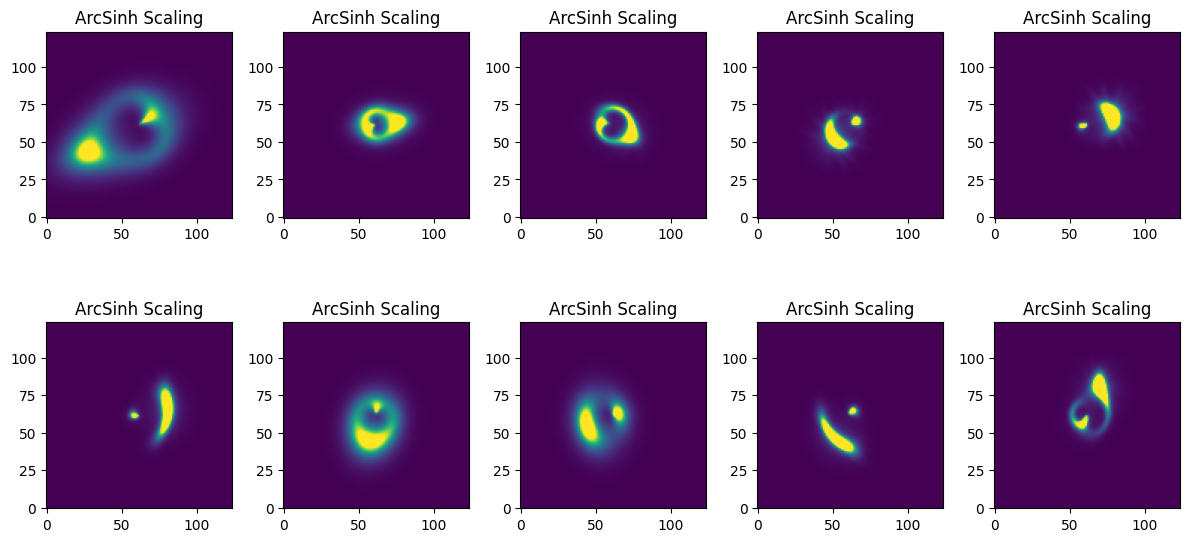

Lens 0: measured mag = 21.11, metadata mag = 20.56
Lens 1: measured mag = 23.06, metadata mag = 22.63
Lens 2: measured mag = 23.77, metadata mag = 23.59
Lens 3: measured mag = 24.62, metadata mag = 24.30
Lens 4: measured mag = 24.96, metadata mag = 24.26
Lens 5: measured mag = 23.38, metadata mag = 23.00
Lens 6: measured mag = 22.75, metadata mag = 22.74
Lens 7: measured mag = 22.21, metadata mag = 22.33
Lens 8: measured mag = 24.29, metadata mag = 23.89
Lens 9: measured mag = 24.26, metadata mag = 23.72


In [20]:
#estimating the magnitiude of the source but 
#instead sum the fluxes that are above the background  flux 

from astropy.stats import sigma_clipped_stats

def estimate_background(image, sigma=3.0, maxiters=5):
    """Background and noise from sigma-clipped stats (rejects bright source pixels)."""
    mean, median, std = sigma_clipped_stats(image, sigma=sigma, maxiters=maxiters)
    return median, std

def flux_above_background(image, background_median, background_std=None, n_sigma=1.0):
    """
    Total flux from pixels above background.
    If background_std is given, only sum pixels with (pixel - background) > n_sigma * background_std.
    """
    excess = image - background_median
    if background_std is not None and background_std > 0:
        mask = excess > n_sigma * background_std #only sum pixels with (pixel - background) > 1.0* background_std
    else:
        mask = excess > 0
    return np.sum(excess[mask])


ap_photometry_no_deflector = []
fig, axes = plt.subplots(2, 5, figsize=(12, 6))
n_sigma_threshold = 1.0  # only sum pixels > background + 1*sigma (tune: 0.5–2)

for i, lens in enumerate(test_lens_list):  # or test_lens_list[0:2]
    arcsinh_scaling_lens = simulate_roman_image(
        lens, band="F129", num_pix=124, oversample=5,
        add_noise=False, with_deflector=False
    )

    # Background from sigma-clipped stats (source pixels are clipped out)
    bkg_median, bkg_std = estimate_background(arcsinh_scaling_lens, sigma=3.0, maxiters=5)

    # Total flux = sum of (pixel - background) for pixels above threshold
    source_flux = flux_above_background(
        arcsinh_scaling_lens,
        bkg_median,
        background_std=bkg_std,
        n_sigma=n_sigma_threshold,
    )

    source_mag = -2.5 * np.log10(source_flux) + mag_zero_point if source_flux > 0 else np.nan
    ap_photometry_no_deflector.append({"flux": source_flux, "mag": source_mag})

    # Plot
    ax = axes[i // 5, i % 5]
    img = np.arcsinh(arcsinh_scaling_lens)
    vmin, vmax = np.percentile(img, [1, 99])
    ax.imshow(img, origin="lower", cmap="viridis", vmin=vmin, vmax=vmax)
    ax.set_title("ArcSinh Scaling")
    print(f"Lens {i}: source flux = {source_flux:.2f}, source mag = {source_mag:.2f}")

plt.tight_layout()
plt.show()

#compare the two methods of estimating the magnitude of the source 
for i, lens in enumerate(test_lens_list):
    meta_mag = lens.extended_source_magnitude("F129", lensed=True)[0]
    print(f"Lens {i}: measured mag = {ap_photometry_no_deflector[i]['mag']:.2f}, metadata mag = {meta_mag:.2f}")


In [21]:
test_lens_list[0].deflector_position

array([-0.02964307,  0.0149254 ])

Lens 0: deflector flux = 195.72, deflector mag = 20.22
Lens 1: deflector flux = 19393.57, deflector mag = 15.23
Lens 2: deflector flux = 102.80, deflector mag = 20.92
Lens 3: deflector flux = 6257.82, deflector mag = 16.46
Lens 4: deflector flux = 65.87, deflector mag = 21.40
Lens 5: deflector flux = 3118.63, deflector mag = 17.22
Lens 6: deflector flux = 33.90, deflector mag = 22.12
Lens 7: deflector flux = 281.76, deflector mag = 19.83
Lens 8: deflector flux = 31.20, deflector mag = 22.21
Lens 9: deflector flux = 376.13, deflector mag = 19.51


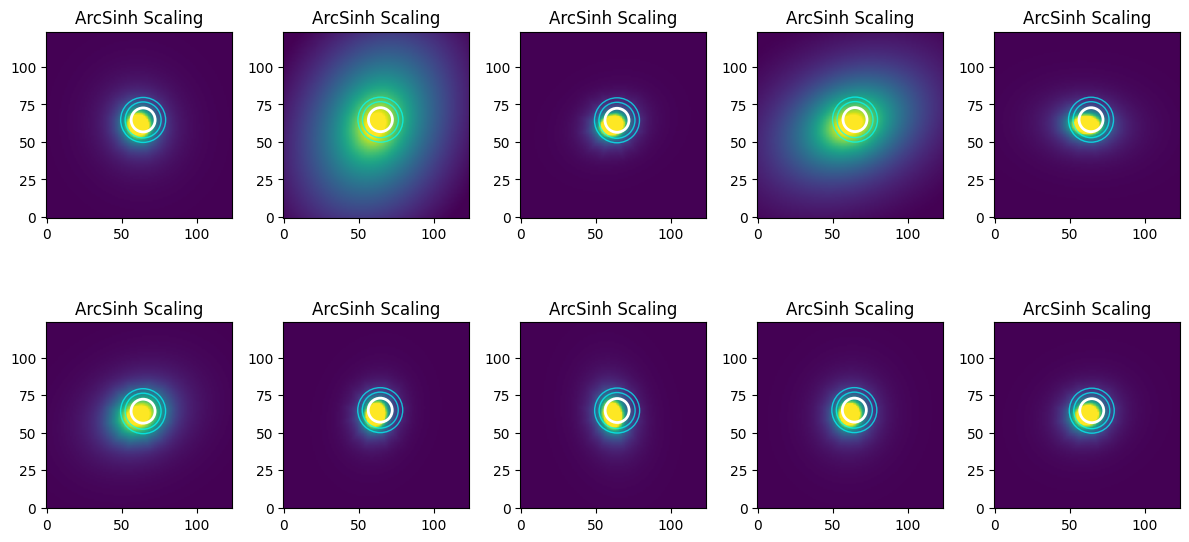

NameError: name 'deflector_mags' is not defined

In [22]:
 # measure the magnitude of the deflector, use circular apertures 

ap_photometry_no_source = []
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

#do a list of inner and outer annulus for the 10 objects 


for i, lens in enumerate(test_lens_list):  # or test_lens_list for all 10
    arcsinh_scaling_lens = simulate_roman_image(
        lens, band="F129", num_pix=124, oversample=5,
        add_noise=False, with_deflector=True, with_source=False)
    ax = axes[i // 5, i % 5]
    img = np.arcsinh(arcsinh_scaling_lens)
    vmin, vmax = np.percentile(img, [1, 99])
    ax.imshow(img, origin="lower", cmap="viridis", vmin=vmin, vmax=vmax)
    ax.set_title("ArcSinh Scaling")

    # Lensed image positions (arcsec) for source 0
    #pos_list = lens.point_source_image_positions()[0]
    pos_list = lens.deflector_position
    #print(pos_list)
    #x_arcsec, y_arcsec = np.array(pos_list[0]), np.array(pos_list[1])
    x_arcsec = np.atleast_1d(np.asarray(pos_list[0]))
    y_arcsec = np.atleast_1d(np.asarray(pos_list[1]))
    #print(x_arcsec, y_arcsec)

    # Convert to pixel coordinates
    pix_positions = [arcsec_to_pixel(x, y) for x, y in zip(x_arcsec, y_arcsec)]

    # One circular aperture per image; sum flux from all
    apertures = [CircularAperture((pix_x, pix_y), r=aperture_radius)
                 for pix_x, pix_y in pix_positions]
    # Background: annulus at first image (or use a single large annulus away from arcs)
    bx, by = pix_positions[0]
    annulus = CircularAnnulus((bx, by), r_in=inner_annulus, r_out=outer_annulus)

    # Background (one annulus)
    bkg_phot = aperture_photometry(arcsinh_scaling_lens, annulus)
    mean_bkg_per_pix = bkg_phot["aperture_sum"].value[0] / annulus.area

    # Photometry per aperture, then sum
    total_flux = 0.0
    for ap in apertures:
        phot = aperture_photometry(arcsinh_scaling_lens, ap)
        total_flux += phot["aperture_sum"].value[0] - mean_bkg_per_pix * ap.area

    deflector_flux = total_flux
    deflector_mag = -2.5 * np.log10(deflector_flux) + mag_zero_point if deflector_flux > 0 else np.nan
    ap_photometry_no_source.append({"flux": deflector_flux, "mag": deflector_mag})

    # Plot apertures
    for ap in apertures:
        ap.plot(ax=ax, color="white", lw=2)
    annulus.plot(ax=ax, color="cyan", lw=1, alpha=0.7)
    print(f"Lens {i}: deflector flux = {deflector_flux:.2f}, deflector mag = {deflector_mag:.2f}")

plt.tight_layout()
plt.show()

for i, lens in enumerate(test_lens_list):
    meta_mag = lens.deflector_magnitude("F129")
    print(f"Lens {i}: measured mag = {deflector_mags[i]:.2f}, metadata mag = {meta_mag:.2f}")


Lens 0: deflector flux = 206.73, deflector mag = 20.16
Lens 1: deflector flux = 99.64, deflector mag = 20.95
Lens 2: deflector flux = 341.20, deflector mag = 19.62
Lens 3: deflector flux = 455.92, deflector mag = 19.30
Lens 4: deflector flux = 453.61, deflector mag = 19.31
Lens 5: deflector flux = 3868.51, deflector mag = 16.98
Lens 6: deflector flux = 104.27, deflector mag = 20.90
Lens 7: deflector flux = 633.82, deflector mag = 18.95
Lens 8: deflector flux = 1214.86, deflector mag = 18.24
Lens 9: deflector flux = 300.82, deflector mag = 19.75


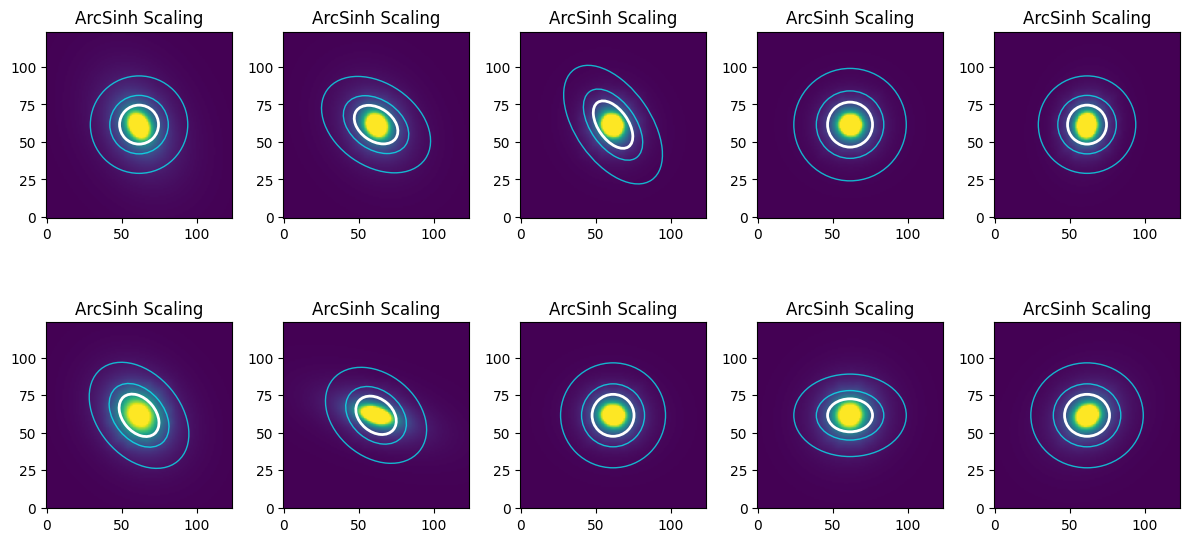

Lens 0: measured mag = 20.16, metadata mag = 19.06
Lens 1: measured mag = 20.95, metadata mag = 20.19
Lens 2: measured mag = 19.62, metadata mag = 19.16
Lens 3: measured mag = 19.30, metadata mag = 18.92
Lens 4: measured mag = 19.31, metadata mag = 18.92
Lens 5: measured mag = 16.98, metadata mag = 16.44
Lens 6: measured mag = 20.90, metadata mag = 20.21
Lens 7: measured mag = 18.95, metadata mag = 18.51
Lens 8: measured mag = 18.24, metadata mag = 17.62
Lens 9: measured mag = 19.75, metadata mag = 19.15


In [ ]:
 # measure the magnitude of the deflector only to make sure to use elliptical apertures 

import numpy as np
import matplotlib.pyplot as plt
from photutils.aperture import aperture_photometry, EllipticalAperture, EllipticalAnnulus

# --- Simulation params (match your simulate_roman_image call) ---
num_pix = 124
num_pix_sim = num_pix # + 6  # 130
center_x = (num_pix_sim - 1) / 2.0
center_y = (num_pix_sim - 1) / 2.0
mag_zero_point = 25.95  # adjust to your band

# --- Ellipse params: (a, b, theta_deg) — same for all or one per lens ---
# Single set for all deflectors:
# a_pix = 15
# b_pix = 12
# theta_rad = np.deg2rad(0.0)
r_in, r_out = 1.5, 2.5  # annulus: inner/outer multiple of a, b

# Optional: per-lens ellipses (uncomment and use in loop instead of a_pix, b_pix, theta_rad above)
ellipse_params = [
    (13, 13, 0),     # 0 top-left: circular
    (16, 11, -35),    # 1 top 2nd: elongated, angled
    (18, 10, -55),   # 2 top 3rd: elongated, angled
    (15, 15, 0),     # 3 top 4th: circular
    (13, 13, 0),     # 4 top right: circular
    (16, 11, -50),    # 5 bottom-left: elongated, angled
    (15, 11, -40),   # 6 bottom 2nd: elongated, angled
    (14, 14, 0),     # 7 bottom 3rd: circular (adjust if this one also has angle)
    (15, 11, 0),     # 8 bottom 4th: elongated, no angle
    (15, 14, 0),     # 9 bottom right: slight ellipse
]

fig, axes = plt.subplots(2, 5, figsize=(12, 6))
deflector_fluxes = []
deflector_mags = []

for i, lens in enumerate(test_lens_list):
    deflector_image = simulate_roman_image(
        lens, band="F129", num_pix=num_pix, oversample=5,
        add_noise=False, with_deflector=True, with_source=False
    )

    # Use per-lens params if you defined ellipse_params (uncomment the 3 lines below)
    a_pix, b_pix, theta_deg = ellipse_params[i]
    theta_rad = np.deg2rad(theta_deg)

    aperture = EllipticalAperture((center_x, center_y), a=a_pix, b=b_pix, theta=theta_rad)
    annulus = EllipticalAnnulus(
        (center_x, center_y),
        a_in=r_in * a_pix, a_out=r_out * a_pix,
        b_in=r_in * b_pix, b_out=r_out * b_pix,
        theta=theta_rad,
    )

    bkg_phot = aperture_photometry(deflector_image, annulus)
    mean_bkg_per_pix = bkg_phot["aperture_sum"].value[0] / annulus.area
    phot = aperture_photometry(deflector_image, aperture)
    deflector_flux = phot["aperture_sum"].value[0] - mean_bkg_per_pix * aperture.area
    deflector_fluxes.append(deflector_flux)

    deflector_mag = -2.5 * np.log10(deflector_flux) + mag_zero_point if deflector_flux > 0 else np.nan
    deflector_mags.append(deflector_mag)

    ax = axes[i // 5, i % 5]
    img = np.arcsinh(deflector_image)
    vmin, vmax = np.percentile(img, [1, 99])
    ax.imshow(img, origin="lower", cmap="viridis", vmin=vmin, vmax=vmax)
    ax.set_title("ArcSinh Scaling")
    aperture.plot(ax=ax, color="white", lw=2)
    annulus.plot(ax=ax, color="cyan", lw=1, alpha=0.7)
    print(f"Lens {i}: deflector flux = {deflector_flux:.2f}, deflector mag = {deflector_mag:.2f}")

plt.tight_layout()
plt.show()

# Optional: compare to metadata
for i, lens in enumerate(test_lens_list):
    meta_mag = lens.deflector_magnitude("F129")
    print(f"Lens {i}: measured mag = {deflector_mags[i]:.2f}, metadata mag = {meta_mag:.2f}")


/opt/miniconda3/envs/slsim/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:2605: RuntimeWarning: invalid value encountered in do_format (vectorized)
  outputs = ufunc(*inputs)


Lens 0: SNR = 1.71, source_flux_corrected = 0.89, n_pixels = 27, noise_flux = 0.52


/opt/miniconda3/envs/slsim/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:2605: RuntimeWarning: invalid value encountered in do_format (vectorized)
  outputs = ufunc(*inputs)


Lens 1: SNR = 1.92, source_flux_corrected = 1.24, n_pixels = 42, noise_flux = 0.65


/opt/miniconda3/envs/slsim/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:2605: RuntimeWarning: invalid value encountered in do_format (vectorized)
  outputs = ufunc(*inputs)


...

Lens 7: SNR = 2.12, source_flux_corrected = 1.36, n_pixels = 40, noise_flux = 0.64


/opt/miniconda3/envs/slsim/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:2605: RuntimeWarning: invalid value encountered in do_format (vectorized)
  outputs = ufunc(*inputs)


Lens 8: SNR = 1.47, source_flux_corrected = 0.77, n_pixels = 27, noise_flux = 0.52


/opt/miniconda3/envs/slsim/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:2605: RuntimeWarning: invalid value encountered in do_format (vectorized)
  outputs = ufunc(*inputs)


Lens 9: SNR = 2.17, source_flux_corrected = 1.26, n_pixels = 33, noise_flux = 0.58


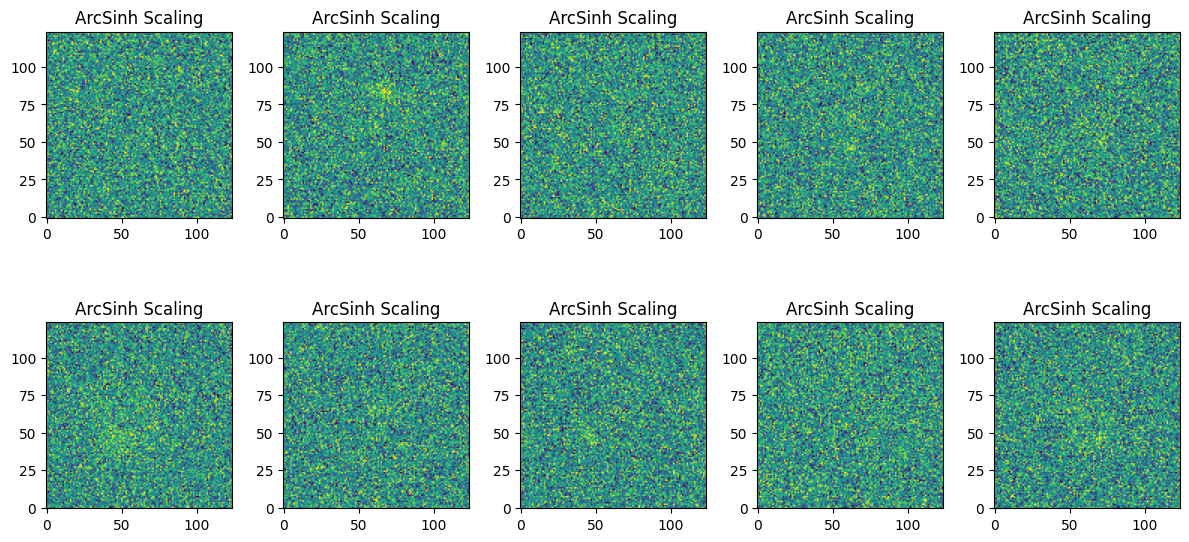

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.stats import sigma_clipped_stats
from scipy.stats import norm

def estimate_background(image, sigma=3.0, maxiters=5):
    mean, median, std = sigma_clipped_stats(image, sigma=sigma, maxiters=maxiters)
    return median, std

def flux_above_background_and_n_pixels(image, background_median, background_std=None, n_sigma=1.0):
    excess = image - background_median
    if background_std is not None and background_std > 0:
        mask = excess > n_sigma * background_std
    else:
        mask = excess > 0
    total_flux = np.sum(excess[mask])
    n_pixels = np.sum(mask) #number of pixels above the background
    return total_flux, n_pixels

def bias_excess_above_threshold(n_sigma):
    """Mean excess (in units of sigma) for pixels above n_sigma, under pure Gaussian noise."""
    z0 = float(n_sigma)
    return z0 + norm.pdf(z0) / (1 - norm.cdf(-z0)) #bias factor

n_sigma = 3.0
bias_factor = bias_excess_above_threshold(n_sigma)  # ~3.15 for n_sigma=3

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, lens in enumerate(test_lens_list):
    source_image_with_noise = simulate_roman_image(
        lens, band="F129", num_pix=124, oversample=5,
        add_noise=True, with_deflector=False, with_source=True
    )
    ax = axes[i // 5, i % 5]
    img = np.arcsinh(source_image_with_noise)
    vmin, vmax = np.percentile(img, [1, 99])
    ax.imshow(img, origin="lower", cmap="viridis", vmin=vmin, vmax=vmax)
    ax.set_title("ArcSinh Scaling")

    background_median, background_std = estimate_background(
        source_image_with_noise, sigma=3.0, maxiters=5
    )
    source_flux, n_pixels = flux_above_background_and_n_pixels(
        source_image_with_noise, background_median, background_std, n_sigma=n_sigma
    )

    # Bias: expected sum from pure noise when selecting pixels above n_sigma
    expected_flux_from_noise = n_pixels * background_std * bias_factor
    source_flux_corrected = source_flux - expected_flux_from_noise #subtract the expected flux from the noise

    noise_flux = np.sqrt(n_pixels) * background_std
    snr = source_flux_corrected / noise_flux if noise_flux > 0 else 0.0
    snr = max(0.0, snr)

    print(f"Lens {i}: SNR = {snr:.2f}, source_flux_corrected = {source_flux_corrected:.2f}, "
          f"n_pixels = {n_pixels}, noise_flux = {noise_flux:.2f}")

plt.tight_layout()
plt.show()

/opt/miniconda3/envs/slsim/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:2605: RuntimeWarning: invalid value encountered in do_format (vectorized)
  outputs = ufunc(*inputs)


lenght of the image = 15376
n_pixels = 23
Lens 0: SNR = 0.59
source flux = 7.38
noise flux = 12.46


/opt/miniconda3/envs/slsim/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:2605: RuntimeWarning: invalid value encountered in do_format (vectorized)
  outputs = ufunc(*inputs)


lenght of the image = 15376
n_pixels = 38
Lens 1: SNR = 0.99
source flux = 12.43
noise flux = 12.51


/opt/miniconda3/envs/slsim/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:2605: RuntimeWarning: invalid value encountered in do_format (vectorized)
  outputs = ufunc(*inputs)


...

lenght of the image = 15376
n_pixels = 25
Lens 7: SNR = 0.67
source flux = 8.38
noise flux = 12.59


/opt/miniconda3/envs/slsim/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:2605: RuntimeWarning: invalid value encountered in do_format (vectorized)
  outputs = ufunc(*inputs)


lenght of the image = 15376
n_pixels = 34
Lens 8: SNR = 0.91
source flux = 11.31
noise flux = 12.38


/opt/miniconda3/envs/slsim/lib/python3.10/site-packages/numpy/lib/_function_base_impl.py:2605: RuntimeWarning: invalid value encountered in do_format (vectorized)
  outputs = ufunc(*inputs)


lenght of the image = 15376
n_pixels = 34
Lens 9: SNR = 0.90
source flux = 11.18
noise flux = 12.46


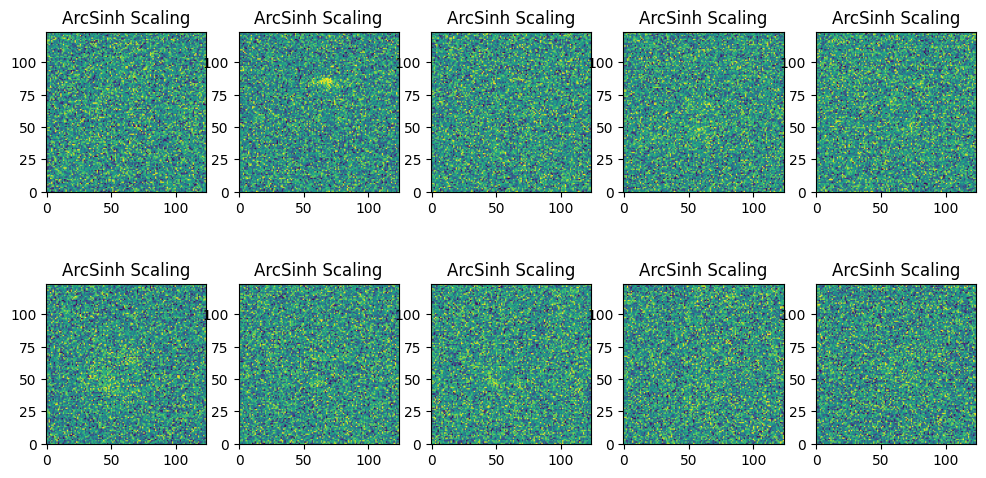

In [ ]:
#estimate the signal to noise ratio of the source with the noise set to True 

def estimate_signal_to_noise(image, background_median, background_std=None, n_sigma=1.0):
    """
    Estimate signal-to-noise ratio (SNR) of source in image.
    """
    snr = image / background_std
    return snr


def flux_above_background_and_n_pixels(image, background_median, background_std=None, n_sigma=1.0):
    excess = image - background_median
    if background_std is not None and background_std > 0:
        mask = excess > n_sigma * background_std
    else:
        mask = excess > 0
    total_flux = np.sum(excess[mask])
    n_pixels = np.sum(mask)
    return total_flux, n_pixels


fig, axes = plt.subplots(2, 5, figsize=(12, 6))   

for i, lens in enumerate(test_lens_list):
    source_image_with_noise = simulate_roman_image(
        lens, band="F129", num_pix=124, oversample=5,
        add_noise=True, with_deflector=False, with_source=True
    )
    #plot the image 
    ax = axes[i // 5, i % 5]
    img = np.arcsinh(source_image_with_noise)
    vmin, vmax = np.percentile(img, [1, 99])
    ax.imshow(img, origin="lower", cmap="viridis", vmin=vmin, vmax=vmax)
    ax.set_title("ArcSinh Scaling")
    

    background_median, background_std = estimate_background(source_image_with_noise, sigma=3.0, maxiters=5)
    source_flux, n_pixels = flux_above_background_and_n_pixels(source_image_with_noise, background_median, background_std, n_sigma=3.0)
    n_pixels_background  = source_image_with_noise.size - n_pixels
    noise_flux = np.sqrt(n_pixels_background) * background_std
    #print(f"lenght of source flux = {len(source_flux)}")
    print(f"lenght of the image = {source_image_with_noise.size}")
    print(f"n_pixels = {n_pixels}")
    snr = source_flux / noise_flux
    print(f"Lens {i}: SNR = {snr:.2f}")
    print(f"source flux = {source_flux:.2f}")
    #print(f"background median = {background_median:.2f}")
    print(f"noise flux = {noise_flux:.2f}")

plt.show()



In [ ]:

lens_population = lens_pop.draw_population(kwargs_lens_cuts=kwargs_lens_cut_plot)
print("Number of lenses:", len(lens_population))

lens_samples = []
labels = [
    r"$\sigma_v$",
    r"$\log(M_{*})$",
    r"$\theta_E$",
    r"$z_{\rm l}$",
    r"$z_{\rm s}$",
    r"$m_{\rm source}$",
    r"$m_{\rm lens}$",
]

for gg_lens in lens_population:
    vel_disp = gg_lens.deflector_velocity_dispersion()
    m_star = gg_lens.deflector_stellar_mass()
    theta_e = gg_lens.einstein_radius[0]
    zl = gg_lens.deflector_redshift
    zs = gg_lens.source_redshift_list[0]
    source_mag = gg_lens.extended_source_magnitude(band="F129", lensed=True)[0]
    deflector_mag = gg_lens.deflector_magnitude(band="F129")

    lens_samples.append(
        [vel_disp, np.log10(m_star), theta_e, zl, zs, source_mag, deflector_mag]
    )

Number of lenses: 30


In [ ]:
print([vel_disp, np.log10(m_star), theta_e, zl, zs, source_mag, deflector_mag])


[np.float64(299.1756104856124), np.float64(11.922695277144122), np.float64(1.221099572922512), 1.5224025271664765, 4.29934477670317, np.float64(24.327867964027753), np.float64(20.24533649968225)]


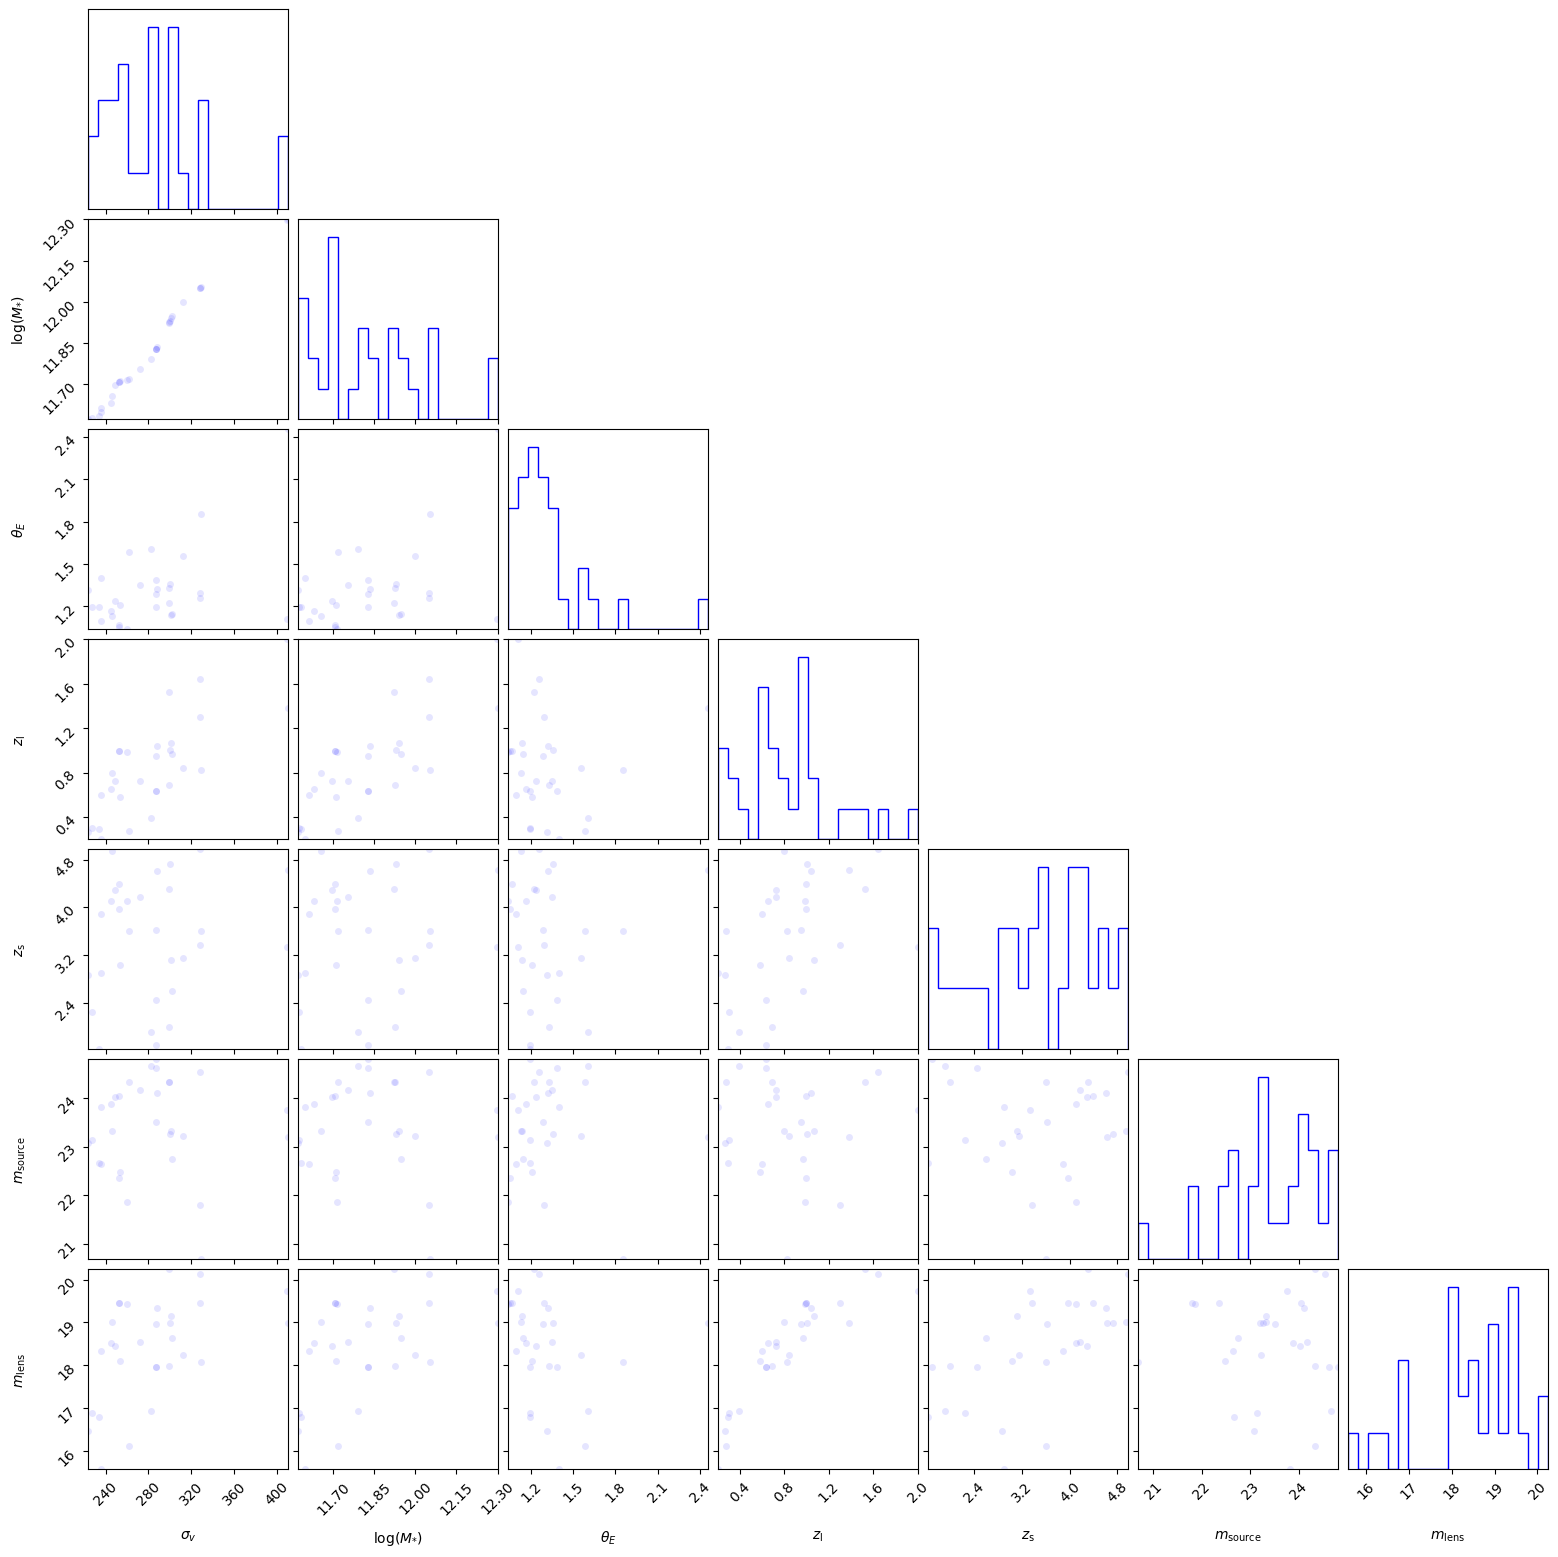

In [ ]:
hist2dkwargs = {
    "plot_density": False,
    "plot_contours": False,
    "plot_datapoints": True,
    "color": "b",
    "data_kwargs": {"ms": 5},
}
corner.corner(np.array(lens_samples), labels=labels, **hist2dkwargs)
plt.show()